In [40]:
import tensorflow as tf
import numpy as np
import cv2
import matplotlib.pyplot as plt

print("TensorFlow version:", tf.__version__)
print("Libraries loaded successfully.")

TensorFlow version: 2.17.0
Libraries loaded successfully.


In [148]:
model = tf.keras.models.load_model(
    "pneumonia_densenet121_20Epochs_model.h5"
)

print("Model loaded successfully.")
print("Input shape:", model.input_shape)
print("Output shape:", model.output_shape)

Model loaded successfully.
Input shape: (None, 224, 224, 3)
Output shape: (None, 1)


In [149]:
base_model = model.layers[0]

print("Base model:", base_model.name)
print("Number of layers:", len(base_model.layers))
print("Base model output shape:", base_model.output_shape)

Base model: densenet121
Number of layers: 427
Base model output shape: (None, 7, 7, 1024)


In [150]:
for layer in base_model.layers[-30:]:
    print(layer.name, "->", layer.__class__.__name__)

conv5_block13_0_bn -> BatchNormalization
conv5_block13_0_relu -> Activation
conv5_block13_1_conv -> Conv2D
conv5_block13_1_bn -> BatchNormalization
conv5_block13_1_relu -> Activation
conv5_block13_2_conv -> Conv2D
conv5_block13_concat -> Concatenate
conv5_block14_0_bn -> BatchNormalization
conv5_block14_0_relu -> Activation
conv5_block14_1_conv -> Conv2D
conv5_block14_1_bn -> BatchNormalization
conv5_block14_1_relu -> Activation
conv5_block14_2_conv -> Conv2D
conv5_block14_concat -> Concatenate
conv5_block15_0_bn -> BatchNormalization
conv5_block15_0_relu -> Activation
conv5_block15_1_conv -> Conv2D
conv5_block15_1_bn -> BatchNormalization
conv5_block15_1_relu -> Activation
conv5_block15_2_conv -> Conv2D
conv5_block15_concat -> Concatenate
conv5_block16_0_bn -> BatchNormalization
conv5_block16_0_relu -> Activation
conv5_block16_1_conv -> Conv2D
conv5_block16_1_bn -> BatchNormalization
conv5_block16_1_relu -> Activation
conv5_block16_2_conv -> Conv2D
conv5_block16_concat -> Concatenate


In [151]:
target_layer = base_model.get_layer("conv5_block16_2_conv")

print("Grad-CAM layer:", target_layer.name)
print("Number of filters:", target_layer.filters)

Grad-CAM layer: conv5_block16_2_conv
Number of filters: 32


In [152]:
def preprocess_image(path):
    img = tf.keras.preprocessing.image.load_img(
        path,
        target_size=(224, 224)
    )

    img = tf.keras.preprocessing.image.img_to_array(img)

    img = np.expand_dims(img, axis=0)

    img = img / 255.0

    return img

In [483]:
img_path = r"C:\Users\usER\Downloads\Data Analysis\master\Phd\chest_xray_new\val\NORMAL\NORMAL2-IM-0233-0001.jpeg"

img_array = preprocess_image(img_path)

print("Image prepared successfully.")
print("Image shape:", img_array.shape)
print("Minimum pixel value:", img_array.min())
print("Maximum pixel value:", img_array.max())

Image prepared successfully.
Image shape: (1, 224, 224, 3)
Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [484]:
prediction = model.predict(img_array, verbose=0)

probability = float(prediction[0][0])

print("Prediction probability:", probability)

if probability >= 0.5:
    predicted_class = "Pneumonia"
else:
    predicted_class = "Normal"

print("Predicted class:", predicted_class)

Prediction probability: 0.8613949418067932
Predicted class: Pneumonia


In [485]:
def gradcam(img_array):

    # Model that returns the target convolutional
    # feature maps and the DenseNet121 output
    grad_model = tf.keras.models.Model(
        inputs=base_model.input,
        outputs=[
            target_layer.output,
            base_model.output
        ]
    )

    with tf.GradientTape() as tape:

        # Forward pass through DenseNet121
        conv_outputs, base_output = grad_model(
            img_array,
            training=False
        )

        # Pass DenseNet features through the classifier
        x = base_output

        for layer in model.layers[1:]:
            x = layer(x, training=False)

        predictions = x[:, 0]

        # Explain the predicted class
        if float(predictions[0]) >= 0.5:
            target = predictions
        else:
            target = 1.0 - predictions

    # Calculate gradients
    grads = tape.gradient(
        target,
        conv_outputs
    )

    # Global average pooling of gradients
    pooled_grads = tf.reduce_mean(
        grads,
        axis=(0, 1, 2)
    )

    # Remove batch dimension
    conv_outputs = conv_outputs[0]

    # Weight feature maps by their gradients
    heatmap = tf.reduce_sum(
        conv_outputs * pooled_grads,
        axis=-1
    )

    # ReLU
    heatmap = tf.maximum(
        heatmap,
        0
    )

    # Normalize for visualization
    heatmap = heatmap / (
        tf.reduce_max(heatmap)
        + tf.keras.backend.epsilon()
    )

    return heatmap.numpy()

In [486]:
heatmap = gradcam(img_array)

print("Heatmap generated successfully.")
print("Heatmap shape:", heatmap.shape)
print("Heatmap minimum:", heatmap.min())
print("Heatmap maximum:", heatmap.max())

Heatmap generated successfully.
Heatmap shape: (7, 7)
Heatmap minimum: 0.0
Heatmap maximum: 0.9999161


In [487]:
def show_gradcam(img_path, heatmap):

    # Load original X-ray
    original = cv2.imread(img_path)
    original = cv2.cvtColor(original, cv2.COLOR_BGR2RGB)
    original = cv2.resize(original, (224, 224))

    # Resize Grad-CAM heatmap
    heatmap_resized = cv2.resize(
        heatmap,
        (224, 224),
        interpolation=cv2.INTER_LINEAR
    )

    # Convert heatmap to 0–255
    heatmap_uint8 = np.uint8(255 * heatmap_resized)

    # Apply JET colormap
    heatmap_color = cv2.applyColorMap(
        heatmap_uint8,
        cv2.COLORMAP_JET
    )

    # Convert BGR to RGB
    heatmap_color = cv2.cvtColor(
        heatmap_color,
        cv2.COLOR_BGR2RGB
    )

    # Create overlay
    overlay = cv2.addWeighted(
        original,
        0.6,
        heatmap_color,
        0.4,
        0
    )

    # Create figure
    plt.figure(figsize=(15, 5))

    # 1. Original X-ray
    plt.subplot(1, 3, 1)
    plt.imshow(original)
    plt.title("Original X-ray", fontsize=14)
    plt.axis("off")

    # 2. Grad-CAM heatmap
    plt.subplot(1, 3, 2)
    plt.imshow(heatmap_resized, cmap="jet")
    plt.title("Grad-CAM Heatmap", fontsize=14)
    plt.axis("off")

    # 3. Grad-CAM overlay
    plt.subplot(1, 3, 3)
    plt.imshow(overlay)
    plt.title("Grad-CAM Overlay", fontsize=14)
    plt.axis("off")

    plt.tight_layout()
    plt.show()

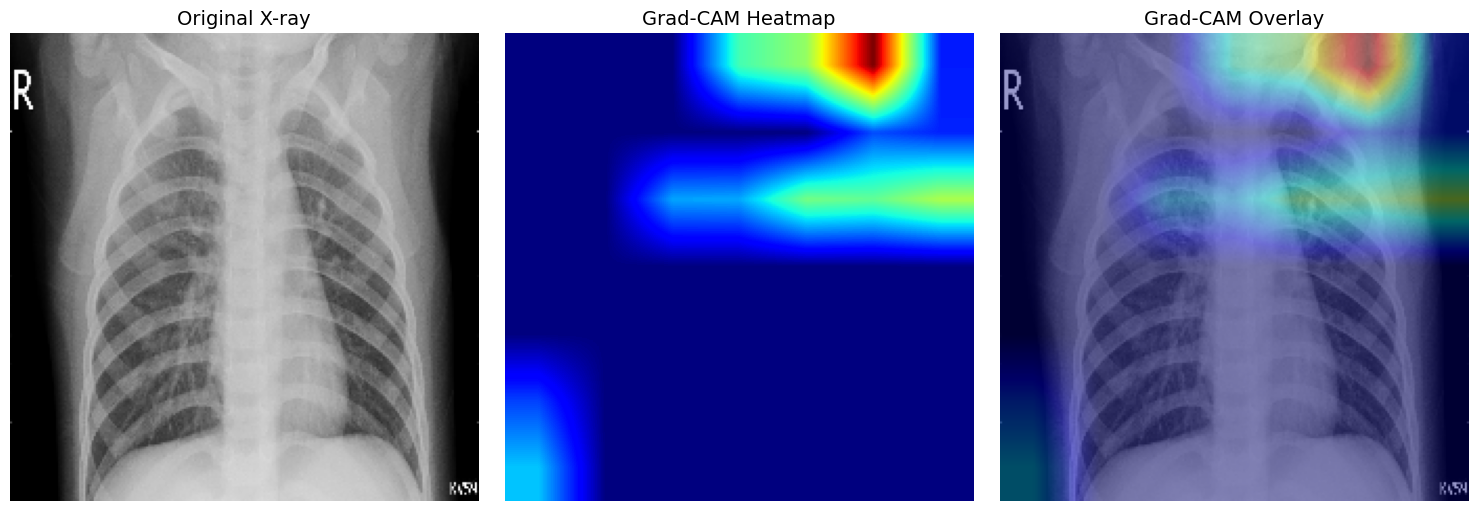

In [488]:
show_gradcam(img_path, heatmap)